# Проект:предсказание виновности в ДТП

<b>Описание:</b> Сервис каршеринга собрал данные, требуется создать систему предсказания риска ДТП, для предупреждения родителя. Под риском понимается вероятность ДТП с любым повреждением транспортного средства. 

<b>Цель:</b> предсказать есть ли риск, что клиент станет виновником ДТП для выбранного маршрута

<b>Задачи:</b> Загрзить данные из базы данных, провести предобработку данных, исследовательский анализ данных, провести статистический анализ и обучить модель. После обучения требуется провести анализ важности признаков

<b>Исходные данные:</b> Нам дана реляционная база данных, с четырьмся сущностями - связующая таблица с индексом и годом базы данных, таблица с данными о транспортных средствах, таблица с данными о происшествиях, таблица с данными об участниках происшествия

Для начала подгрузим библиотеки

In [1]:
!pip install phik -q

In [2]:
!pip install category_encoders -q

In [3]:
!pip install scikit-learn==1.1.3 -q

In [4]:
!pip install sqlalchemy -q

In [5]:
!pip install shap -q

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import shap

from sqlalchemy import create_engine 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from category_encoders import CatBoostEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, precision_score, recall_score

from phik import phik_matrix
from phik.report import plot_correlation_matrix

from catboost import CatBoostClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression 
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

In [7]:
RANDOM_STATE = 42
TEST_SIZE = 0.25

## Подключитесь к базе. Загрузите таблицы sql

Напишем строку для подключения к базе данных

In [8]:
db_config = {
'user': 'praktikum_student',
'pwd': 'Sdf4$2;d-d30pp',
'host': 'rc1b-wcoijxj3yxfsf3fs.mdb.yandexcloud.net',
'port': 6432,
'db': 'data-science-vehicle-db',
} 

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
) 

Подключаемся к базе

In [9]:
engine = create_engine(connection_string) 

Давайте считаем наши таблицы по отдельности, для ознакомления с данными

In [10]:
query_id = '''
SELECT *
FROM case_ids
'''

query_v = '''
SELECT *
FROM vehicles
'''

query_с = '''
SELECT *
FROM collisions
'''

query_p = '''
SELECT *
FROM parties
'''

In [11]:
data_p = pd.read_sql_query(query_p, con = engine)

In [12]:
data_c = pd.read_sql_query(query_с, con = engine)

In [13]:
data_v = pd.read_sql_query(query_v, con = engine)

In [14]:
data_id = pd.read_sql_query(query_id, con = engine)

## Проведите первичное исследование таблиц

Напишем класс для исследования таблиц(здесь будем использовать функцию intro, а все остальные пригодятся в конце на финальном наборе данных)

In [15]:
class EDA:
    
    def __init__(self, df):
        self.df = df
        
    def intro(self):
        if self.df is None:
            print('Все плохо')
            return
        
        print('Первые пять строк и базовая инфа')
        display(self.df.head(5))
        display(self.df.describe())
        self.df.info()
        
    def feature_display(self, int_cols, cat_cols):
        if self.df is None:
            print('Все плохо')
            return
        
        print('Гистограммы непрерывных признаков')
        for column in int_cols:
            
            fig, ax = plt.subplots(figsize=(8, 5))
            sns.histplot(self.df, x=column,
                 kde=True, kde_kws={'bw_method': 0.6}, edgecolor='white', ax=ax)
            ax.set_title(f'Распределение признака\n«{column}»')
            ax.set_xlabel(column)
            ax.set_ylabel('Количество')
            plt.show()
            
        print('Столбчатые диаграммы для категориальных признаков')
        for column in cat_cols:
            counts = self.df[column].value_counts()
            plt.figure(figsize=(10,4))
            sns.barplot(x=counts.sort_values(ascending=False).index, 
                        y=counts.values, 
                        palette="viridis")
            plt.xticks(rotation=90)
            plt.tight_layout()
            plt.title(column)
            plt.show()
        
    def phik_matrix(self):
        phik_overview = self.df.phik_matrix(interval_cols = int_cols)
        plt.figure(figsize=(20, 12))
        sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
        plt.title("Матрица корреляций")
        plt.show()

Выведем базовую информацию о связующей таблице с идентификаторами ДТП

In [16]:
case_ids = EDA(data_id)
df_id = case_ids.df
case_ids.intro()

Первые пять строк и базовая инфа


,case_id,db_year
0,0081715,2021
1,0726202,2021
2,3858022,2021
3,3899441,2021
4,3899442,2021


,case_id,db_year
count,1400000,1400000
unique,1400000,1
top,5500945,2021
freq,1,1400000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400000 entries, 0 to 1399999
Data columns (total 2 columns):
 #   Column   Non-Null Count    Dtype 
---  ------   --------------    ----- 
 0   case_id  1400000 non-null  object
 1   db_year  1400000 non-null  object
dtypes: object(2)
memory usage: 21.4+ MB


Полный набор данных содержит 1400000 случаев ДТП, данная таблица корректно считалась и соответствует заданию

In [17]:
collisions = EDA(data_c)
df_c = collisions.df
collisions.intro()

Первые пять строк и базовая инфа


,case_id,county_city_location,county_location,distance,direction,intersection,weather_1,location_type,collision_damage,party_count,primary_collision_factor,pcf_violation_category,type_of_collision,motor_vehicle_involved_with,road_surface,road_condition_1,lighting,control_device,collision_date,collision_time
0,4083072,1942,los angeles,528.0,north,0.0,cloudy,highway,small damage,2,vehicle code violation,unsafe lane change,sideswipe,other motor vehicle,wet,normal,daylight,none,2009-01-22,07:25:00
1,4083075,4313,santa clara,0.0,None,1.0,clear,None,small damage,1,vehicle code violation,improper passing,hit object,fixed object,dry,normal,dark with street lights,functioning,2009-01-03,02:26:00
2,4083073,0109,alameda,0.0,None,1.0,clear,None,scratch,2,vehicle code violation,improper turning,broadside,other motor vehicle,dry,normal,dark with street lights,functioning,2009-01-11,03:32:00
3,4083077,0109,alameda,0.0,None,1.0,clear,None,scratch,2,vehicle code violation,automobile right of way,broadside,other motor vehicle,dry,normal,daylight,functioning,2009-01-11,10:35:00
4,4083087,4313,santa clara,0.0,None,1.0,clear,None,scratch,2,vehicle code violation,speeding,rear end,other motor vehicle,dry,None,dark with street lights,functioning,2009-01-02,22:43:00


,distance,intersection,party_count
count,1.400000e+06,1.387781e+06,1.400000e+06
mean,6.607115e+02,2.249087e-01,1.966006e+00
std,1.178579e+04,4.175223e-01,6.724457e-01
min,0.000000e+00,0.000000e+00,1.000000e+00
25%,2.000000e+00,0.000000e+00,2.000000e+00
50%,1.000000e+02,0.000000e+00,2.000000e+00
75%,4.300000e+02,0.000000e+00,2.000000e+00
max,8.363520e+06,1.000000e+00,2.700000e+01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400000 entries, 0 to 1399999
Data columns (total 20 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   case_id                      1400000 non-null  object 
 1   county_city_location         1400000 non-null  object 
 2   county_location              1400000 non-null  object 
 3   distance                     1400000 non-null  float64
 4   direction                    1059358 non-null  object 
 5   intersection                 1387781 non-null  float64
 6   weather_1                    1392741 non-null  object 
 7   location_type                518779 non-null   object 
 8   collision_damage             1400000 non-null  object 
 9   party_count                  1400000 non-null  int64  
 10  primary_collision_factor     1391834 non-null  object 
 11  pcf_violation_category       1372046 non-null  object 
 12  type_of_collision            1388176 non-n

Таблица с характеристиками ДТП имеет в себе некоторое количество пропусков - по большей части их мало, но в полях с типом дороги и направлением движения их много, к счастью эти поля нам не потребуются при обучении модели, так что не страшно. По поводу наличия полей - все заявленные поля присутствуют, в том числе и ключ

In [18]:
vehicles = EDA(data_v)
df_v = vehicles.df
vehicles.intro()

Первые пять строк и базовая инфа


,id,case_id,party_number,vehicle_type,vehicle_transmission,vehicle_age
0,1175713,5305032,2,sedan,manual,3.0
1,1,3858022,1,sedan,auto,3.0
2,1175712,5305030,1,sedan,auto,3.0
3,1175717,5305033,3,sedan,auto,5.0
4,1175722,5305034,2,sedan,auto,5.0


,id,party_number,vehicle_age
count,1.021234e+06,1.021234e+06,996652.000000
mean,7.601628e+05,1.609510e+00,5.137088
std,4.386194e+05,6.790946e-01,3.110310
min,1.000000e+00,1.000000e+00,0.000000
25%,3.806942e+05,1.000000e+00,3.000000
50%,7.617625e+05,2.000000e+00,5.000000
75%,1.141348e+06,2.000000e+00,7.000000
max,1.517654e+06,2.700000e+01,161.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1021234 entries, 0 to 1021233
Data columns (total 6 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   id                    1021234 non-null  int64  
 1   case_id               1021234 non-null  object 
 2   party_number          1021234 non-null  int64  
 3   vehicle_type          1021234 non-null  object 
 4   vehicle_transmission  997575 non-null   object 
 5   vehicle_age           996652 non-null   float64
dtypes: float64(1), int64(2), object(3)
memory usage: 46.7+ MB


Таблица с данными о транспортных средствах считалась, все поля из условия есть, ключ есть, но к сожалению набор данных неполон, так как количество записей меньше чем в предыдущих таблицах, а должно быть больше, так как case_id у нас должен быть неуникальным, так как в ДТП часто участвуют более одного транспортного средства

In [19]:
parties = EDA(data_p)
df_p = parties.df
parties.intro()

Первые пять строк и базовая инфа


,id,case_id,party_number,party_type,at_fault,insurance_premium,party_sobriety,party_drug_physical,cellphone_in_use
0,22,3899454,1,road signs,1,29.0,had not been drinking,None,0.0
1,23,3899454,2,road signs,0,7.0,had not been drinking,None,0.0
2,29,3899462,2,car,0,21.0,had not been drinking,None,0.0
3,31,3899465,2,road signs,0,24.0,had not been drinking,None,0.0
4,41,3899478,2,road bumper,0,NaN,not applicable,not applicable,0.0


,id,party_number,at_fault,insurance_premium,cellphone_in_use
count,2.752408e+06,2.752408e+06,2.752408e+06,2.347006e+06,2.240771e+06
mean,1.376204e+06,1.598029e+00,4.680000e-01,3.874724e+01,2.045055e-02
std,7.945519e+05,7.236567e-01,4.989750e-01,1.637851e+01,1.415356e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.881028e+05,1.000000e+00,0.000000e+00,2.500000e+01,0.000000e+00
50%,1.376204e+06,1.000000e+00,0.000000e+00,3.600000e+01,0.000000e+00
75%,2.064306e+06,2.000000e+00,1.000000e+00,5.000000e+01,0.000000e+00
max,2.752408e+06,2.700000e+01,1.000000e+00,1.050000e+02,1.000000e+00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2752408 entries, 0 to 2752407
Data columns (total 9 columns):
 #   Column               Dtype  
---  ------               -----  
 0   id                   int64  
 1   case_id              object 
 2   party_number         int64  
 3   party_type           object 
 4   at_fault             int64  
 5   insurance_premium    float64
 6   party_sobriety       object 
 7   party_drug_physical  object 
 8   cellphone_in_use     float64
dtypes: float64(2), int64(3), object(4)
memory usage: 189.0+ MB


In [20]:
display(df_p.isna().sum())

id                           0
case_id                      0
party_number                 0
party_type                3622
at_fault                     0
insurance_premium       405402
party_sobriety           73955
party_drug_physical    2320120
cellphone_in_use        511637
dtype: int64

Таблица с данными об участниках считалась корректно, все поля есть, ключ тоже. Ключ здесь тоже неуникальный, но в отличие от таблицы с ТС тут количество записей похоже на правду, так как превосходит количество уникальных ключей почти в два раза. Набор данных неполный, присутствует значительное количество пропусков в некоторых полях: страховка, использование телефона, а поле с физическим состоянием клиента почти полностью состоит из пропусков 

##  Проведите статистический анализ факторов ДТП

Требуется оценить как влияет месяц на вероятность проишествия ДТП

In [10]:
query_stat = '''
SELECT 
    EXTRACT(MONTH FROM collision_date) as month,
    EXTRACT(YEAR FROM collision_date) as year
FROM collisions
'''

In [11]:
data_month = pd.read_sql_query(query_stat, con = engine)

In [12]:
month = pd.pivot_table(data_month,values='month',index='year',aggfunc=[lambda x: x.isnull().sum(),'count'])

In [13]:
display(month)

,<lambda>,count
,month,month
year,,
2009.0,0.0,426228
2010.0,0.0,416490
2011.0,0.0,402428
2012.0,0.0,154547
2013.0,0.0,305
2020.0,0.0,2


В 2013 и 2020 недостаточно данных, убираем их

In [14]:
data_month = data_month[(data_month['year']!=2013) & (data_month['year']!=2020) & (data_month['year']!=2012)]

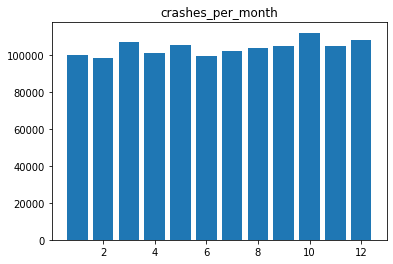

In [15]:
plt.title('crashes_per_month')
plt.bar(data_month['month'].value_counts().index, data_month['month'].value_counts().values)
plt.show()

Распределение равномерное

<b/>Задачи для моих любимых колег:<b/>

- Какая коробка передач соответствует наибольшему числу виновников ДТП
    - Создайте sql-запрос
    - Постройте график
    - Сделайте вывод

In [26]:
query_trans = '''
WITH t AS (
    SELECT
        case_id,
        at_fault
    FROM parties),
v AS (
    SELECT
        case_id,
        vehicle_transmission
    FROM vehicles)

SELECT *
FROM t
JOIN v ON t.case_id = v.case_id 
'''

In [27]:
data_trans = pd.read_sql_query(query_trans, con = engine)

In [28]:
data_trans = data_trans[data_trans['at_fault']==1]

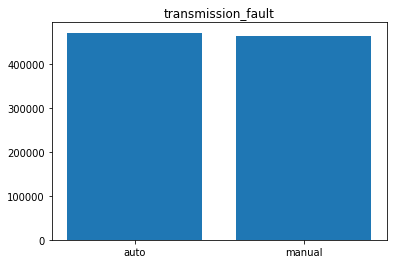

In [29]:
plt.title('transmission_fault')
plt.bar(data_trans['vehicle_transmission'].value_counts().index, data_trans['vehicle_transmission'].value_counts().values)
plt.show()

На основе этой диаграммы можно сделать вывод, что водители автоматов и механик равномерно попадают в ДТП, хотя водители механик слегка меньше

- Как связаны признаки наличия страховки и виновности в ДТП
    - Создайте sql-запрос
    - Постройте график
    - Сделайте вывод

In [30]:
query_ins = '''
SELECT
    at_fault,
    insurance_premium
FROM parties
'''

In [31]:
data_ins = pd.read_sql_query(query_ins, con = engine)

In [32]:
data_ins_1 = data_ins[data_ins['at_fault']==1]
data_ins_0 = data_ins[data_ins['at_fault']==0]

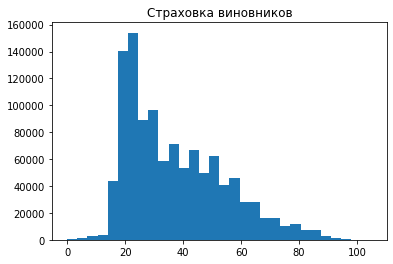

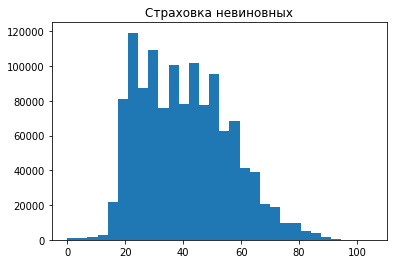

In [33]:
plt.title('Страховка виновников')
plt.hist(data_ins_1['insurance_premium'],bins=30)
plt.show()

plt.title('Страховка невиновных')
plt.hist(data_ins_0['insurance_premium'],bins=30)
plt.show()

Распределение страховки невиновных более, равномерная, то есть после пика в 20, значение страховки снижается более плавно, в то время когда виновники реже имеют страховку среднего объема

- Как связаны признаки наличия страховки и виновности в ДТП
- Как связаны признаки наличия мотоциклиста в ДТП и произошло ли ДТП на перекрестке
- Проанализировать и найти процент ДТП, которые привели к серьезным повреждениям, после которых машина не поддается починке
- Найти в каком районе чаще всего происходят ДТП

## Создайте модель для оценки водительского риска

Напишем финальный запрос, данные с которого пойдут на обучение, требованиями являются то, что урон машине должен быть серьезнее чем царапина, все ДТП должны быть за 2012 год, а виновником ДТП всегда должна быть машина. Были взяты все признаки, которые известны до начала поездки, когда водитель садится и вбивает маршрут

In [34]:
query = '''
WITH t AS (
    SELECT
        party_number,
        case_id,
        at_fault,
        party_type,
        insurance_premium,
        cellphone_in_use
    FROM parties),

c AS (
    SELECT
        case_id,
        county_location,
        weather_1,
        road_surface,
        lighting,
        road_condition_1,
        EXTRACT(DOW FROM collision_date) as dow,
        EXTRACT(HOUR FROM collision_time) as hour
    FROM collisions
    WHERE collision_damage != 'scratch' AND EXTRACT(YEAR FROM collision_date)=2012),
    
v AS (
    SELECT
        case_id,
        party_number,
        vehicle_type,
        vehicle_transmission,
        vehicle_age
    FROM vehicles
)
SELECT *
FROM t
JOIN c ON t.case_id = c.case_id
JOIN v ON t.case_id = v.case_id AND t.party_number = v.party_number
WHERE t.case_id IN (
SELECT
    DISTINCT case_id
FROM parties
WHERE at_fault=1 AND party_type='car'
)
'''

In [35]:
data = pd.read_sql_query(query, con = engine)

In [36]:
final_data = EDA(data)
df_main = final_data.df
final_data.intro()

Первые пять строк и базовая инфа


,party_number,case_id,at_fault,party_type,insurance_premium,cellphone_in_use,case_id,county_location,weather_1,road_surface,lighting,road_condition_1,dow,hour,case_id,party_number,vehicle_type,vehicle_transmission,vehicle_age
0,3,5459722,0,car,20.0,0.0,5459722,fresno,clear,dry,daylight,normal,1.0,15.0,5459722,3,sedan,manual,3.0
1,2,5457178,0,car,33.0,0.0,5457178,los angeles,clear,dry,dark with street lights,construction,0.0,1.0,5457178,2,sedan,manual,6.0
2,2,5457184,0,car,64.0,0.0,5457184,san diego,clear,dry,daylight,normal,1.0,14.0,5457184,2,sedan,auto,2.0
3,2,5468752,0,car,24.0,0.0,5468752,sacramento,raining,wet,dark with street lights,normal,6.0,19.0,5468752,2,sedan,manual,NaN
4,1,5468457,1,car,16.0,0.0,5468457,tuolumne,clear,dry,dark with no street lights,normal,5.0,20.0,5468457,1,coupe,manual,2.0


,party_number,at_fault,insurance_premium,cellphone_in_use,dow,hour,party_number,vehicle_age
count,55616.000000,55616.000000,54495.000000,50568.000000,55616.000000,55524.000000,55616.000000,54027.000000
mean,1.564532,0.510159,37.348858,0.020408,3.155063,13.298285,1.564532,4.874156
std,0.677563,0.499901,16.484501,0.141393,2.043757,5.523982,0.677563,3.237480
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,1.000000,0.000000,23.000000,0.000000,1.000000,10.000000,1.000000,3.000000
50%,1.000000,1.000000,34.000000,0.000000,3.000000,14.000000,1.000000,4.000000
75%,2.000000,1.000000,48.000000,0.000000,5.000000,17.000000,2.000000,7.000000
max,9.000000,1.000000,102.000000,1.000000,6.000000,23.000000,9.000000,161.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55616 entries, 0 to 55615
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   party_number          55616 non-null  int64  
 1   case_id               55616 non-null  object 
 2   at_fault              55616 non-null  int64  
 3   party_type            55589 non-null  object 
 4   insurance_premium     54495 non-null  float64
 5   cellphone_in_use      50568 non-null  float64
 6   case_id               55616 non-null  object 
 7   county_location       55616 non-null  object 
 8   weather_1             55465 non-null  object 
 9   road_surface          55279 non-null  object 
 10  lighting              55474 non-null  object 
 11  road_condition_1      55380 non-null  object 
 12  dow                   55616 non-null  float64
 13  hour                  55524 non-null  float64
 14  case_id               55616 non-null  object 
 15  party_number       

Все считалось корректно, есть небольшое количество пропусков, их мы удалим

Избавимся от столбцов, которые нужны были для правильного отбора и не будут участвовать в моделировании

In [37]:
df_main = df_main.drop(['party_number','case_id','party_type'],axis=1)

Так как число пропусков ничтожно мало, предлагаю их удалить, так как они могут мешать некоторым моделям, которые мы будем использовать

In [38]:
df_main = df_main.dropna()

Посчитаем количество явных дубликатов

In [39]:
display(df_main.duplicated().sum())

672

In [40]:
df_main = df_main.drop_duplicates()

Проверим, что по неявным дубликатам

In [41]:
int_cols = [
    'insurance_premium',
    'vehicle_age']

cat_cols = [
    'at_fault',
    'county_location',
    'weather_1',
    'road_surface',
    'lighting',
    'road_condition_1',
    'vehicle_type',
    'vehicle_transmission',
    'dow',
    'cellphone_in_use']

In [42]:
for column in cat_cols:
    print('Значения признака и их упоминания у признака', column)
    display(df_main[column].value_counts())
    print()

Значения признака и их упоминания у признака at_fault


1    24218
0    22744
Name: at_fault, dtype: int64


Значения признака и их упоминания у признака county_location


los angeles        13308
orange              4497
san diego           3069
san bernardino      3024
riverside           2804
sacramento          1868
alameda             1453
santa clara         1413
ventura             1304
kern                1304
fresno               949
san mateo            871
contra costa         837
san joaquin          819
sonoma               624
tulare               606
santa barbara        599
stanislaus           572
monterey             496
solano               474
placer               465
san francisco        439
san luis obispo      361
santa cruz           352
merced               342
marin                337
humboldt             281
el dorado            266
madera               265
yolo                 245
butte                242
kings                233
shasta               218
napa                 190
imperial             180
mendocino            170
nevada               156
sutter               135
tehama               119
tuolumne             117



Значения признака и их упоминания у признака weather_1


clear      37579
cloudy      7248
raining     1802
fog          152
snowing      142
other         29
wind          10
Name: weather_1, dtype: int64

... (10 outputs left out)


Значения признака и их упоминания у признака dow


5.0    7829
6.0    7695
0.0    6659
4.0    6532
3.0    6353
2.0    6014
1.0    5880
Name: dow, dtype: int64


Значения признака и их упоминания у признака cellphone_in_use


0.0    45996
1.0      966
Name: cellphone_in_use, dtype: int64

In [43]:
final_data.df = df_main

Неявных дубликатов нет, а насчет города подозрения подтвердились, очень много категорий

Гистограммы непрерывных признаков


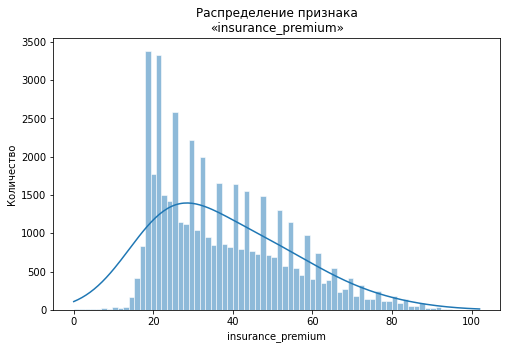

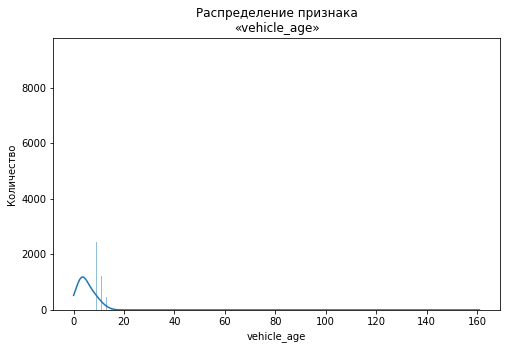

Столбчатые диаграммы для категориальных признаков


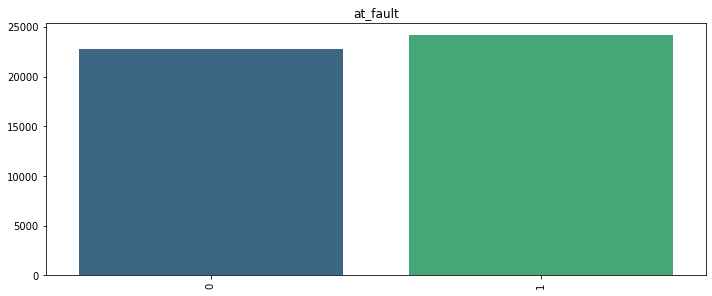

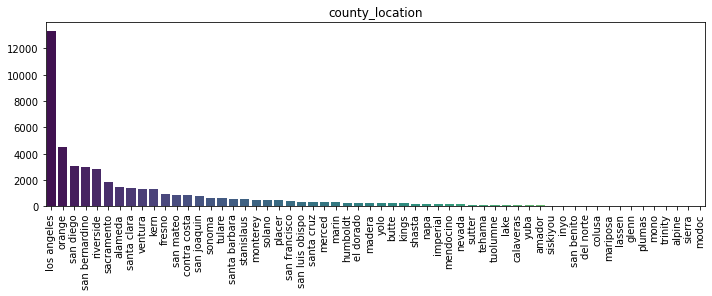

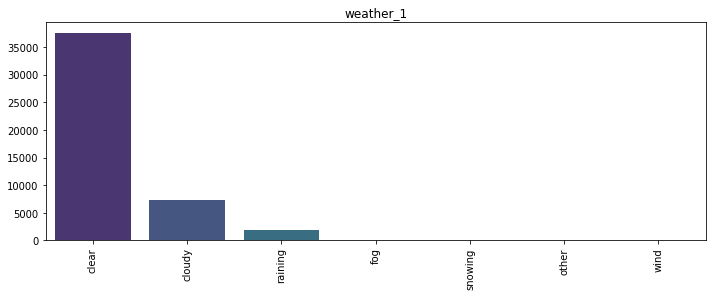

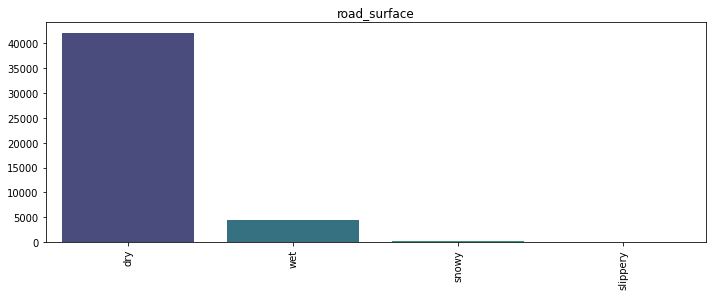

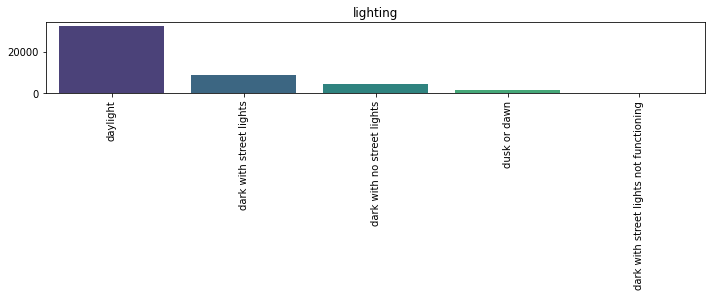

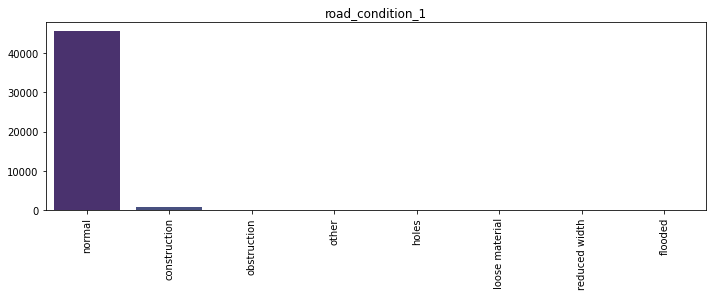

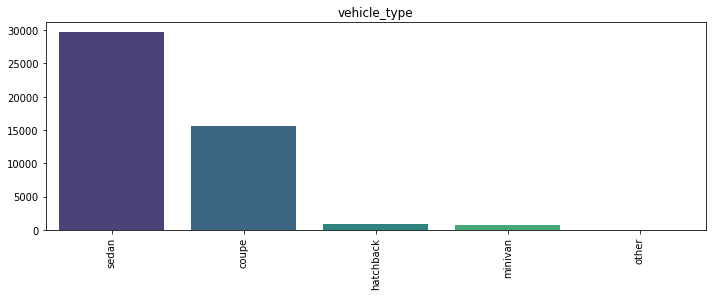

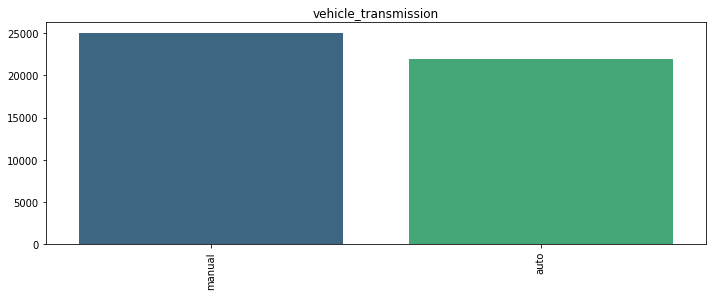

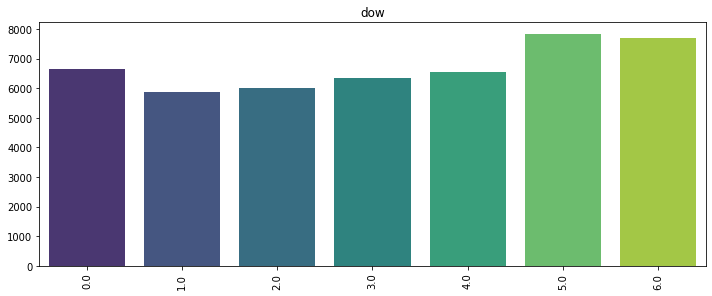

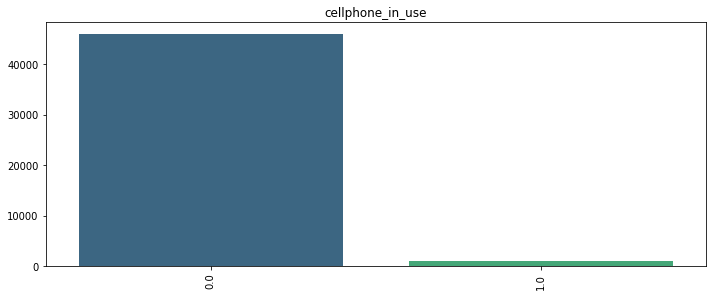

In [44]:
final_data.feature_display(int_cols,cat_cols)

Распределение признака страховки имеет ассиметрию с пиком в значении 20, признак возраста машины тоже имеет ассиметрию, но с пиком в значении около 8 лет. Таргетная переменная имеет равномерное распределение, то есть виновников и невиновных примерно равное количество. Наибольше число ДТП происходят в Лос-Анджелесе, видимо потому что этой самый большой город из представленных. Большая часть ДТП происходит в ясную погоду, когда покрытие дороги сухое, когда сама дорога хорошо освещена и находится в нормальном состоянии. Также большинство ДТП происходит с водителями механик, можно предположить, что это из за того, что управление механикой труднее и в экстримальной ситуации люди хуже справляются с управлением. Наибольшее число ДТП происходит в выходные дни, хотя распределение все еще близко к равномерному и разница не драматична, насчет признака наличия телефона напротив подавляющее большинство ДТП происходит, когда телефон есть, думаю это связано с тем, что нынче принято носить телефон при себе, хотя ДТП из за глупости водителя, что решил во время вождения смотреть в экран тоже имеют место

Теперь нарисуем матрицу корреляций

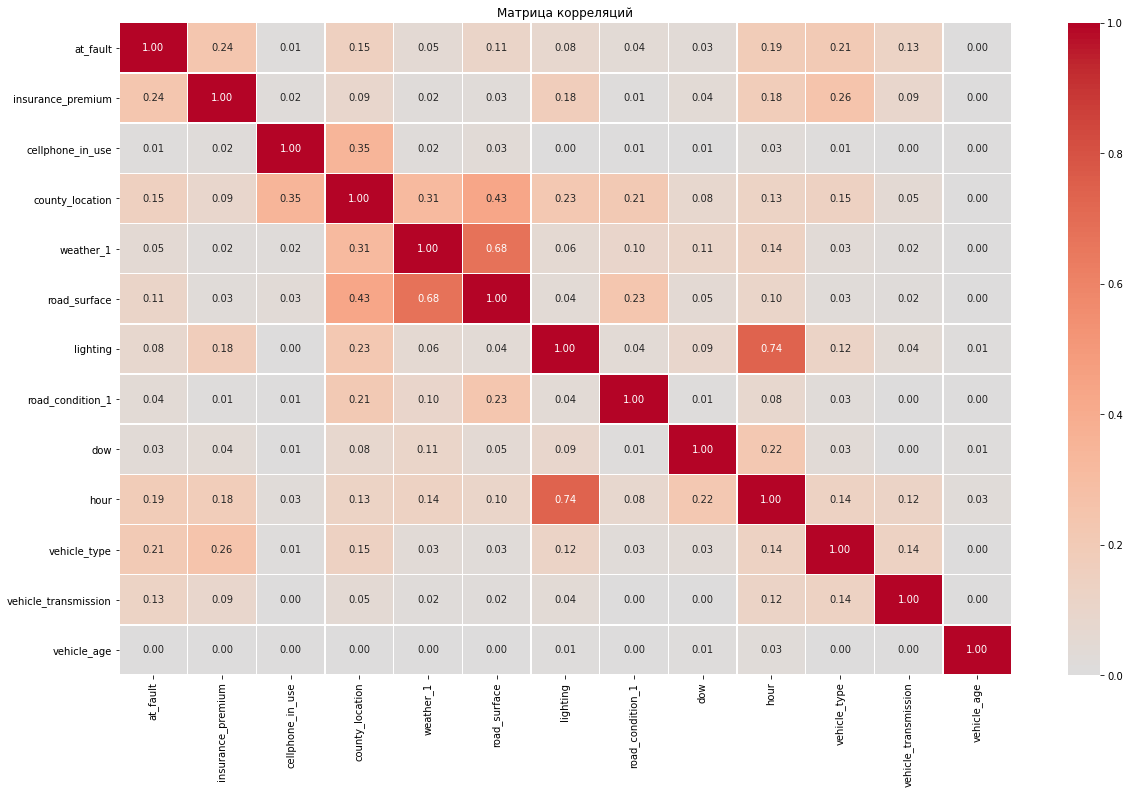

In [45]:
final_data.phik_matrix()

Корреляции с таргетом довольно слабые, но у нас их много, так что это еще не означает, что модель получится плохой, главное, что не нашлось мультиколлинеарности

Разделим наши данные на тренировочную и тестовые выборки

In [46]:
y = df_main['at_fault']
X = df_main.drop('at_fault',axis=1)

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=RANDOM_STATE,test_size=TEST_SIZE)

In [48]:
display(X_train.head(10))

,insurance_premium,cellphone_in_use,county_location,weather_1,road_surface,lighting,road_condition_1,dow,hour,vehicle_type,vehicle_transmission,vehicle_age
39617,61.0,0.0,mendocino,cloudy,wet,daylight,normal,5.0,16.0,coupe,manual,9.0
30328,45.0,0.0,alameda,clear,dry,dusk or dawn,normal,3.0,18.0,sedan,auto,5.0
54276,60.0,0.0,los angeles,clear,dry,dark with street lights,normal,1.0,20.0,minivan,manual,9.0
55294,32.0,0.0,los angeles,clear,dry,dark with street lights,normal,2.0,0.0,coupe,manual,5.0
21213,32.0,0.0,alameda,clear,dry,daylight,normal,5.0,15.0,sedan,auto,3.0
49221,23.0,0.0,butte,raining,wet,daylight,normal,3.0,12.0,sedan,auto,3.0
45441,63.0,0.0,los angeles,cloudy,dry,dark with no street lights,normal,0.0,20.0,sedan,manual,12.0
40554,52.0,0.0,los angeles,clear,dry,dusk or dawn,normal,3.0,17.0,sedan,auto,7.0
25262,55.0,0.0,fresno,clear,dry,daylight,normal,6.0,12.0,sedan,auto,5.0
49124,39.0,0.0,fresno,clear,dry,dark with no street lights,normal,2.0,18.0,coupe,manual,6.0


Напишем пайплайн для обучения наших моделей

In [49]:
int_cols = [
    'insurance_premium',
    'vehicle_age']

cat_cols = [
    'county_location',
    'weather_1',
    'road_surface',
    'lighting',
    'road_condition_1',
    'vehicle_type',
    'vehicle_transmission',]


In [50]:
data_preprocessor = ColumnTransformer(
    [('catboost', CatBoostEncoder(random_state=RANDOM_STATE,verbose=False), cat_cols),
     ('num', StandardScaler(), int_cols)
    ], 
    remainder='passthrough')

In [51]:
pipe_final = Pipeline([
    ('preprocessor', data_preprocessor),
    ('models', DecisionTreeClassifier(random_state=RANDOM_STATE))
])

param_SVC = [
    {
        'models': [SVC(random_state=RANDOM_STATE)],
        'models__kernel': ['linear','poly','rbf','sigmoid'],
        'preprocessor__num': [StandardScaler(), 'passthrough'] 
    }]

param_Tree = [
    {
        'models': [DecisionTreeClassifier(random_state=RANDOM_STATE)],
        'models__max_depth': list(range(2, 6)),  
        'models__max_features': list(range(2, 6)), 
        'preprocessor__num': [StandardScaler(), 'passthrough']
    }]

param_Cat_boost = [
    {
        'models': [CatBoostClassifier(random_state=RANDOM_STATE, verbose=0)], 
        'models__iterations': [100, 300, 500],
        'models__learning_rate': [0.01, 0.05, 0.1],
        'models__depth': [4, 6, 8],
        'preprocessor__num': [StandardScaler(), 'passthrough']
    }]

Объявим переменную для подбора гиперпараметров, в качестве метрики будем использовать roc-auc, потому что нам одинаково важны как метрика recall, так и метрика precision

In [52]:
SVC_search = RandomizedSearchCV(
    pipe_final, 
    param_SVC, 
    cv=5,
    scoring='roc_auc',
    random_state=RANDOM_STATE,
    n_jobs=-1)

Tree_search = RandomizedSearchCV(
    pipe_final, 
    param_Tree, 
    cv=5,
    scoring='roc_auc',
    random_state=RANDOM_STATE,
    n_jobs=-1)

CatBoost_search = RandomizedSearchCV(
    pipe_final, 
    param_Cat_boost, 
    cv=5,
    scoring='roc_auc',
    random_state=RANDOM_STATE,
    n_jobs=-1)

Подберём и выведем лучшие параметры у лучшей модели

In [53]:
Tree_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('catboost',
                                                                               CatBoostEncoder(random_state=42,
                                                                                               verbose=False),
                                                                               ['county_location',
                                                                                'weather_1',
                                                                                'road_surface',
                                                                                'lighting',
                                                                                'road_condition_1',
                                                                                'vehicle_type',
                                                                                'vehicle_transmission']),
                                                                              ('num',
                                                                               StandardScaler(),
                                                                               ['insurance_premium',
                                                                                'vehicle_age'])])),
                                             ('models',
                                              DecisionTreeClassifier(random_state=42))]),
                   n_jobs=-1,
                   param_distributions=[{'models': [DecisionTreeClassifier(max_depth=5,
                                                                           max_features=2,
                                                                           random_state=42)],
                                         'models__max_depth': [2, 3, 4, 5],
                                         'models__max_features': [2, 3, 4, 5],
                                         'preprocessor__num': [StandardScaler(),
                                                               'passthrough']}],
                   random_state=42, scoring='roc_auc')

In [54]:
CatBoost_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('catboost',
                                                                               CatBoostEncoder(random_state=42,
                                                                                               verbose=False),
                                                                               ['county_location',
                                                                                'weather_1',
                                                                                'road_surface',
                                                                                'lighting',
                                                                                'road_condition_1',
                                                                                'vehicle_type',
                                                                                'vehicle_transmission']),
                                                                              ('num',
                                                                               StandardScaler(),
                                                                               ['insurance_premium',
                                                                                'vehicle_age'])])),
                                             ('models',
                                              DecisionTreeClassifier(random_state=42))]),
                   n_jobs=-1,
                   param_distributions=[{'models': [<catboost.core.CatBoostClassifier object at 0x7f759b74a460>],
                                         'models__depth': [4, 6, 8],
                                         'models__iterations': [100, 300, 500],
                                         'models__learning_rate': [0.01, 0.05,
                                                                   0.1],
                                         'preprocessor__num': [StandardScaler(),
                                                               'passthrough']}],
                   random_state=42, scoring='roc_auc')

In [55]:
SVC_search.fit(X_train, y_train)

/opt/conda/lib/python3.9/site-packages/sklearn/model_selection/_search.py:306: UserWarning: The total space of parameters 8 is smaller than n_iter=10. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('catboost',
                                                                               CatBoostEncoder(random_state=42,
                                                                                               verbose=False),
                                                                               ['county_location',
                                                                                'weather_1',
                                                                                'road_surface',
                                                                                'lighting',
                                                                                'road_condition_1',
                                                                                'vehicle_type',
                                                                                'vehicle_transmission']),
                                                                              ('num',
                                                                               StandardScaler(),
                                                                               ['insurance_premium',
                                                                                'vehicle_age'])])),
                                             ('models',
                                              DecisionTreeClassifier(random_state=42))]),
                   n_jobs=-1,
                   param_distributions=[{'models': [SVC(kernel='linear',
                                                        random_state=42)],
                                         'models__kernel': ['linear', 'poly',
                                                            'rbf', 'sigmoid'],
                                         'preprocessor__num': [StandardScaler(),
                                                               'passthrough']}],
                   random_state=42, scoring='roc_auc')

In [56]:
results = [
    ['Дерево решений',Tree_search.best_score_,Tree_search.best_params_],
    ['Катбуст',CatBoost_search.best_score_,CatBoost_search.best_params_],
    ['SVC',SVC_search.best_score_,SVC_search.best_params_]
]

In [57]:
result_df = pd.DataFrame(results,columns=['модель','метрика','гиперапараметры'])

In [58]:
display(result_df)

,модель,метрика,гиперапараметры
0,Дерево решений,0.663066,"{'preprocessor__num': StandardScaler(), 'model..."
1,Катбуст,0.701597,"{'preprocessor__num': StandardScaler(), 'model..."
2,SVC,0.670459,"{'preprocessor__num': 'passthrough', 'models__..."


Лучшей моделью оказался катбуст с метрикой 0.701597

In [59]:
y_pred = CatBoost_search.best_estimator_.predict(X_test)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

<AxesSubplot:>

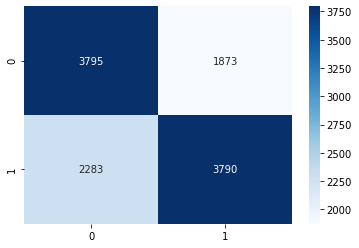

In [60]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True,fmt='d', cmap='Blues')

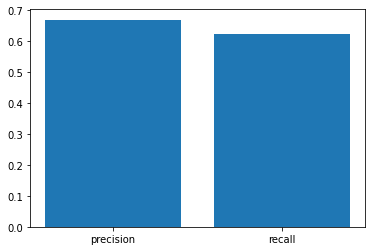

In [61]:
plt.bar(['precision','recall'], [precision,recall])
plt.show()

Метрики получились удовлетворительные, точность и полнота примерно равны, хотя точность слегка отстаёт, но главное, что нам важны оба вида ошибок и результат отвечает нашим требованиям

## Проведите анализ важности факторов ДТП

Напишем код для визуализации важности признаков

In [62]:
best_pipeline = CatBoost_search.best_estimator_

preprocessor = best_pipeline.named_steps['preprocessor']

catboost_model = best_pipeline.named_steps['models']

In [68]:
X_train_preprocessed = preprocessor.transform(X_train)

X_test_preprocessed = preprocessor.transform(X_test)

feature_names = ['insurance_premium','cellphone_in_use'] + cat_cols + ['dow'] + int_cols

In [69]:
X_train_preprocessed_df = pd.DataFrame(X_train_preprocessed, columns=feature_names)
X_test_preprocessed_df = pd.DataFrame(X_test_preprocessed, columns=feature_names)

In [70]:
explainer = shap.TreeExplainer(catboost_model, data=X_train_preprocessed_df)

shap_values = explainer.shap_values(X_test_preprocessed_df)

100%|===================| 11735/11741 [03:26<00:00]        

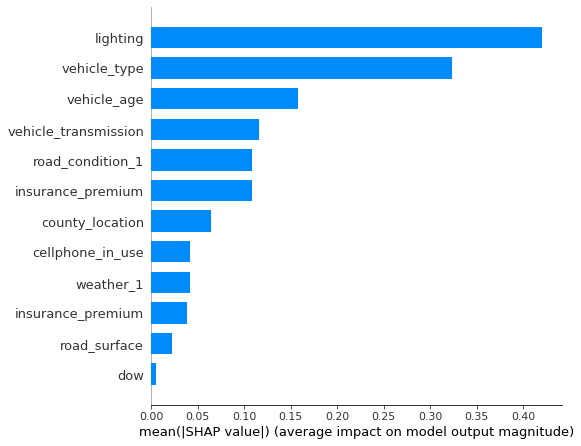

In [71]:
shap.summary_plot(shap_values, X_test_preprocessed_df, plot_type="bar", feature_names=feature_names)

Модель посчитала, что самые важными признаками являются, освещение, тип транспортного средства, его возраст и тип коробки передач. Давайте рассмотрим как зависит освещение и тип транспортного средства от количества ДТП

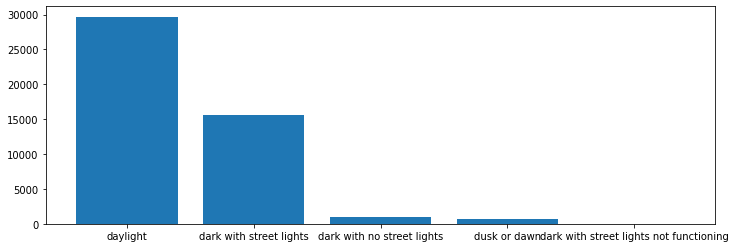

In [90]:
plt.figure(figsize=(12, 4))
plt.bar(df_main['lighting'].value_counts().index, df_main['vehicle_type'].value_counts().values)
plt.show()

На данной диаграмме видно что подавляющее большинство ДТП происходит при дневном свете, либо ночью с фонарями, модели этот признак помог и хорошо, хотя по сути фактической связи нет, было бы еще логично, если бы при отсутствии освещения было много ДТП, но в данном случае превалируют ДТП при дневном свете, что нам говорит о том, что большинство дорожного трафика протекает днем, что и приводит к такому результату анализа

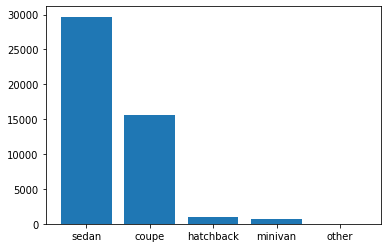

<Figure size 1440x864 with 0 Axes>

In [83]:
plt.bar(df_main['vehicle_type'].value_counts().index, df_main['vehicle_type'].value_counts().values)
plt.figure(figsize=(20, 12))
plt.show()

На данном графике видно, что в большинство ДТП попадают водители седанов и купэ, думаю это связано в первую очередь, что данные виды транспортных средств наиболее популярны и утверждать, что фактор реально влияет в данной ситуации неправильно, так как это все равно, что говорить, что все люди, которые пили воду умерли

## Выводы

Лучшей моделью оказался катбуст, он показал метрику 0.701597, не так плохо. Самыми важными факторами оказались тип транспортного средства и сумма страховки. Думаю модель получилась бы лучше, если бы было больше признаков связанными с данными клиентов, например, история предыдущих ДТП или стаж езды, вместо того же возраста машины